This is the notebook for cleaning and wrangling the wetlands shapefile. Steps include:
1. Adding the Hectares column and subsetting the data to polygons larger than 1 Hectare.
2. Removing shapefile length, shapefile area, and QAQC. 

In [17]:
# import packages
import platform
from pathlib import Path
import pandas as pd
import geopandas as gpd
import pygris
import matplotlib.pyplot as plt

Access Initial Shapefile from Box Drive and read in the shapefile

In [2]:
# set a path to the main box folder based on machine's os
# if windows: 
if platform.system() == 'Windows':
    box_path = Path.home() / 'Box'
# if mac:
else:
    box_path = Path.home() / "Library" / "CloudStorage" / "Box-Box"

#Confirm that the box path is valid
if box_path.exists():
    print(f'Box folder found at {box_path}')
else:
    print(f'Failed to locate the Box folder.\nIs the BoxDrive app running?\nAre you logged in?')

# create path object that goes to the specific folder on Box drive
# uploading wetlands that are bigger than a hectare
wetlands_path = box_path / 'ENVIRON 712L-Students' / 'Data' / 'BunkerAndersonTseng' / 'wetlands' / 'wetlands.shp'
print(wetlands_path.exists())



Box folder found at /Users/katanderson/Library/CloudStorage/Box-Box
True


In [3]:
#read in shp, be PATIENT (took MB 4.5 mins)
wetlands_shp = gpd.read_file(wetlands_path)

Find out information from the wetlands shapefile

In [4]:
wetlands_shp.shape
wetlands_shp.columns


Index(['OBJECTID', 'ATTRIBUTE', 'WETLAND_TY', 'QAQC_CODE', 'ACRES', 'NWI_ID',
       'Shape_Leng', 'Shape_Area', 'geometry'],
      dtype='str')

In [5]:
wetlands_shp.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 891086 entries, 0 to 891085
Data columns (total 9 columns):
 #   Column      Non-Null Count   Dtype   
---  ------      --------------   -----   
 0   OBJECTID    891086 non-null  float64 
 1   ATTRIBUTE   891086 non-null  str     
 2   WETLAND_TY  891086 non-null  str     
 3   QAQC_CODE   22260 non-null   str     
 4   ACRES       891086 non-null  float64 
 5   NWI_ID      891086 non-null  str     
 6   Shape_Leng  891086 non-null  float64 
 7   Shape_Area  891086 non-null  float64 
 8   geometry    891086 non-null  geometry
dtypes: float64(4), geometry(1), str(4)
memory usage: 61.2 MB


Subset the data to only include polygons larger than 1 Hectare (10,000m^2), roughly 20% of the initial data set.

In [6]:
wetlands_shp["Hectares"] = wetlands_shp["Shape_Area"]/10000

wetlands_hectare = wetlands_shp.loc[lambda df: df["Hectares"] > 1]

wetlands_hectare.shape

#calculate subset percent
subset = 179139/891086*100
print(subset)

20.103446805358853


Determine appropriate columns to remain in the cleaned dataset.

In [7]:
wetlands_hectare.head()

,OBJECTID,ATTRIBUTE,WETLAND_TY,QAQC_CODE,ACRES,NWI_ID,Shape_Leng,Shape_Area,geometry,Hectares
2,3.0,R4SBC,Riverine,NaN,9.394554,202409CSw{B818AEF7-DD4D-43B6-A532-1DC94D248F88...,12669.925427,38018.410790,"POLYGON ((-2195423.854 1489042.416, -2195423.8...",3.801841
9,10.0,R4SBC,Riverine,NaN,4.869321,202409CSw{80E28DA5-6244-45AB-9DC9-774ACABD2846...,6572.482823,19705.442594,"POLYGON ((-2197428.286 1494975.476, -2197428.3...",1.970544
11,12.0,R4SBC,Riverine,NaN,7.364585,202409CSw{A66FA93B-E12A-488A-9891-E7526D1AACCE...,9937.020983,29803.416122,"POLYGON ((-2193923.26 1496246.62, -2193923.139...",2.980342
12,13.0,R4SBC,Riverine,NaN,3.099673,202409CSw{B5A926CC-AF98-487F-A4B9-A4789311100A...,4194.847948,12543.932403,"POLYGON ((-2194477.48 1496368.039, -2194475.19...",1.254393
14,15.0,R4SBC,Riverine,NaN,20.027313,202409CSw{C99C89FF-6622-43DE-A93F-138503071611...,26989.063820,81047.662073,"POLYGON ((-2195115.466 1496641.214, -2195115.3...",8.104766


Subset to only Core Columns and rename to be more appropriate

In [8]:
core_cols = ["ATTRIBUTE", "WETLAND_TY","Hectares", "NWI_ID", "geometry"]

wetlands = wetlands_hectare[core_cols]

In [9]:
wetlands = wetlands.rename(
    columns={
        "ATTRIBUTE" : "C Code",
        "WETLAND_TY" : "C Type",
        "NWI_ID": "NWI ID"
    }
)

wetlands.head()
wetlands.shape

(179139, 5)

Write a function to fill in the columns for Cowardin (C) Subsystem and Class

In [10]:
# create additional columns for subsystem and class
#wetlands.insert(2, "C Subsystem", None)
#wetlands.insert(3, "C Class", None)

wetlands.head()

,C Code,C Type,Hectares,NWI ID,geometry
2,R4SBC,Riverine,3.801841,202409CSw{B818AEF7-DD4D-43B6-A532-1DC94D248F88...,"POLYGON ((-2195423.854 1489042.416, -2195423.8..."
9,R4SBC,Riverine,1.970544,202409CSw{80E28DA5-6244-45AB-9DC9-774ACABD2846...,"POLYGON ((-2197428.286 1494975.476, -2197428.3..."
11,R4SBC,Riverine,2.980342,202409CSw{A66FA93B-E12A-488A-9891-E7526D1AACCE...,"POLYGON ((-2193923.26 1496246.62, -2193923.139..."
12,R4SBC,Riverine,1.254393,202409CSw{B5A926CC-AF98-487F-A4B9-A4789311100A...,"POLYGON ((-2194477.48 1496368.039, -2194475.19..."
14,R4SBC,Riverine,8.104766,202409CSw{C99C89FF-6622-43DE-A93F-138503071611...,"POLYGON ((-2195115.466 1496641.214, -2195115.3..."


In [11]:
# generate function to determine the Marine Subsystems
def assign_subsystem(df):
    # marine
    wetlands.loc[lambda df: df["C Code"].str.startswith("M1", na = False), "C Subsystem"] = 'Subtidal'
    wetlands.loc[lambda df: df["C Code"].str.startswith("M2", na = False), "C Subsystem"] = 'Intertidal' 
    # estuarine
    wetlands.loc[lambda df: df["C Code"].str.startswith("E1", na = False), "C Subsystem"] = 'Subtidal'
    wetlands.loc[lambda df: df["C Code"].str.startswith("E2", na = False), "C Subsystem"] = 'Intertidal' 
    # riverine
    wetlands.loc[lambda df: df["C Code"].str.startswith("R1", na = False), "C Subsystem"] = 'Tidal'
    wetlands.loc[lambda df: df["C Code"].str.startswith("R2", na = False), "C Subsystem"] = 'Lower Perennial'
    wetlands.loc[lambda df: df["C Code"].str.startswith("R3", na = False), "C Subsystem"] = 'Upper Perennial'
    wetlands.loc[lambda df: df["C Code"].str.startswith("R4", na = False), "C Subsystem"] = 'Intermittent'
    wetlands.loc[lambda df: df["C Code"].str.startswith("R4", na = False), "C Subsystem"] = 'Unknown Perennial'

    # lacustrine
    wetlands.loc[lambda df: df["C Code"].str.startswith("L1", na = False), "C Subsystem"] = 'Limnetic'
    wetlands.loc[lambda df: df["C Code"].str.startswith("L4", na = False), "C Subsystem"] = 'Littoral'
    # palustrine
    wetlands.loc[lambda df: df["C Code"].str.startswith("P", na = False), "C Subsystem"] = "N/A"
    
    return df

#def assign_class(df):
#    df.loc[df["Cowardin"].str.startswith("PEM", na=False), "class"] = "Emergent"

In [12]:
## apply the subsystem function
wetlands1 = assign_subsystem(wetlands)

wetlands1.sample(12)

,C Code,C Type,Hectares,NWI ID,geometry,C Subsystem
127436,R4SBC,Riverine,1.882288,202409CSw{D873D3BA-C7DA-4743-AB6B-62C76D1FFD4D...,"POLYGON ((-2160455.803 1725305.595, -2160455.8...",Unknown Perennial
267119,PFOA,Freshwater Forested/Shrub Wetland,1.364481,202409CSw{6A385239-EE5C-44EA-B273-763812018D4F...,"POLYGON ((-1920835.896 1329807.591, -1920837.7...",N/A
393412,R4SBJ,Riverine,1.222362,202409CSw{4D026B6C-CD8E-4770-AE44-26170031483D...,"POLYGON ((-1903880.138 1823655.867, -1903880.3...",Unknown Perennial
822109,PEM1J,Freshwater Emergent Wetland,12.393332,202409CSw{1B013805-6E67-4D6A-A2DC-B574112C8C98...,"POLYGON ((-2007703.03 2259578.57, -2007711.141...",N/A
282415,PSS1A,Freshwater Forested/Shrub Wetland,2.819909,202409CSw{EBBEF8BD-29F3-4E1C-B2D6-459F36E6248A...,"POLYGON ((-1698460.593 1333036.228, -1698460.8...",N/A
833437,R4SBA,Riverine,2.492094,202409CSw{4A47D526-F87B-4040-83AB-04572B5DC758...,"POLYGON ((-2150327.939 2215667.485, -2150324.7...",Unknown Perennial
821353,R4SBC,Riverine,1.053822,202409CSw{9ACA703C-673E-4B05-ABE6-674E8CD0F0FB...,"POLYGON ((-2071319.035 2229055.869, -2071319.7...",Unknown Perennial
120249,R4SBJ,Riverine,1.910531,202409CSw{E5627478-274E-4CFD-B4B1-8A8046EDFC1D...,"POLYGON ((-2068153.574 1556925.847, -2068150.4...",Unknown Perennial
820994,PEM1C,Freshwater Emergent Wetland,2.120821,202409CSw{0EC52E27-0FCD-4D30-AA6F-F4A99D70EBB5...,"POLYGON ((-2045026.906 2214949.27, -2044968.61...",N/A
267098,PEM1A,Freshwater Emergent Wetland,33.498941,202409CSw{35EEF3DB-40CB-4C54-95FC-CF48ED5E1D66...,"POLYGON ((-1910123.12 1346340.14, -1910136.73 ...",N/A


Look at the data breakdown thus far

<Axes: xlabel='C Type'>

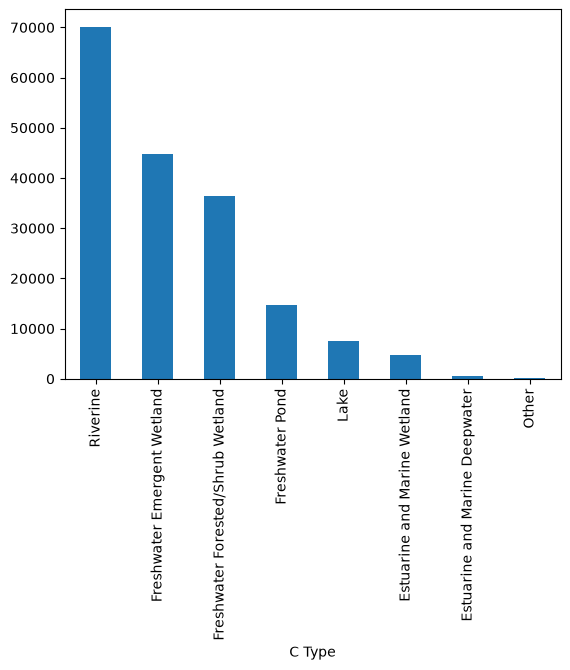

In [14]:
wetlands1["C Type"].value_counts().plot(kind="bar")


<Axes: xlabel='C Subsystem'>

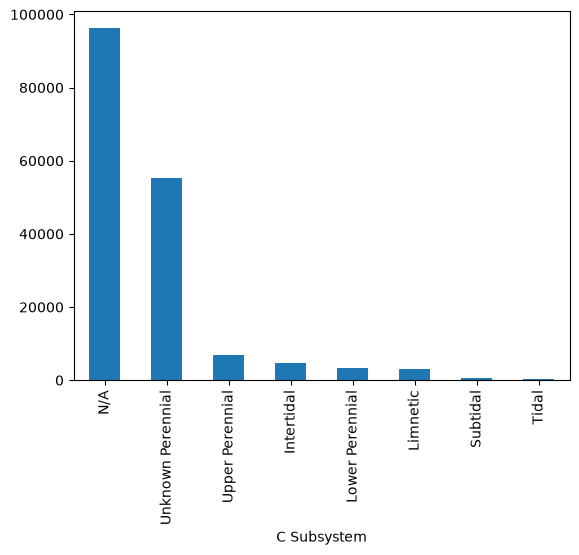

In [15]:
wetlands1["C Subsystem"].value_counts().plot(kind="bar")


Create a map of CA wetlands!

Using the default year of 2024


Text(0.5, 1.0, 'California Wetlands by Cowardin Classification')

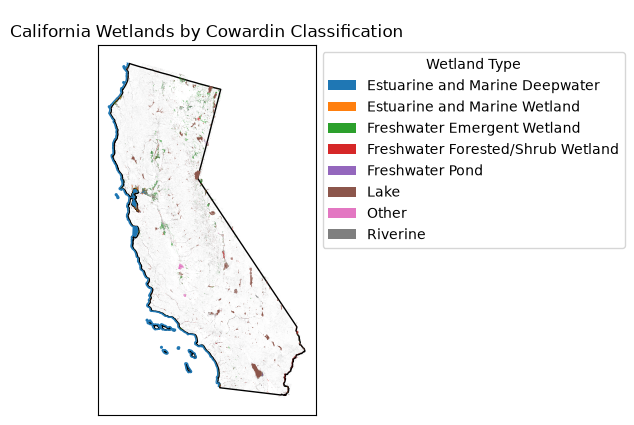

In [21]:
# make a plot of CA wetlands
state_outlines = pygris.states()
state_outlines.head()
ca_outline = state_outlines[state_outlines['NAME'] == 'California']

# make sure CA and wetlands shapefile are in same CRS
ca_outline_proj= ca_outline.to_crs(wetlands1.crs)


# create the empty plot

fig, ax = plt.subplots()
# add the CA outline
ca_outline_proj.plot(ax=ax,color='white',edgecolor='black')
# add the wetlands
# set color by cowardin classification? Legend advice from google gemini
wetlands1.plot(column='C Type',legend=True,ax=ax,figsize=(10,10),
               legend_kwds={
        'loc': 'upper left',       # Moves it to the corner
        'bbox_to_anchor': (1, 1),  # Places it entirely outside the map boundaries
        'title': 'Wetland Type'    # Optional: adds a neat title to your legend box
    })

# consult google gemini to learn how to turn axes off
ax.axis=('off')
ax.get_xaxis().set_visible(False) 
ax.get_yaxis().set_visible(False)

ax.set_title("California Wetlands by Cowardin Classification")
